In [ ]:
### Dans le fichier précédent, on a réalisé l'INFÉRENCE (ce qu'on a vu) :

```
Modèle déjà entraîné
├── Input: Image
└── Output: Détections
```

---

Maintenant, on va parler de l'entraînement d'un modèle de détection d'objets.

### TRAINING (ce qu'on va voir) :

```
Modèle vide (poids aléatoires)
├── Input: Images + Annotations (vérité terrain)
└── Output: Modèle entraîné (poids optimisés)
```


SyntaxError: invalid decimal literal (3446842573.py, line 12)

### INSTALLATION DE DETECTRON2

In [8]:
! pip install detectron2 -f https://dl.fbaipublicfiles.com/detectron2/wheels/cu113/torch1.10/index.html

Looking in links: https://dl.fbaipublicfiles.com/detectron2/wheels/cu113/torch1.10/index.html


### SETUP & IMPORT

In [12]:

import torch
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

import numpy as np
import os, json,  random
import cv2
# from google.colab.patches import cv2_imshow  # Only for Google Colab
import matplotlib.pyplot as plt

# Imports Detectron2
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.structures import BoxMode
from detectron2.engine import HookBase
from detectron2.utils.events import get_event_storage
import detectron2.utils.comm as comm

print("✅ Imports réussis!")
print(f"Detectron2 version: {detectron2.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")


/home/rachidjunior/miniconda3/envs/inseg_proj/lib/python3.10/site-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


✅ Imports réussis!
Detectron2 version: 0.6
PyTorch version: 2.10.0+cpu
CUDA available: False


### CITYSCAPES DATASET LOADING

In [13]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path.home() / "VS_Code" / "INSEG_PRO"
sys.path.insert(0, str(PROJECT_ROOT))

# Import custom dataset loader
from data.dataset_loader import register_cityscapes_dataset, CITYSCAPES_THING_CLASSES

# Define paths
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Register training and validation datasets
print("📂 Loading Cityscapes dataset...")
train_dataset_name, train_dicts, train_metadata = register_cityscapes_dataset(DATA_DIR, split="train")
val_dataset_name, val_dicts, val_metadata = register_cityscapes_dataset(DATA_DIR, split="val")

print(f"✅ Dataset loaded successfully!")
print(f"   Training set: {len(train_dicts)} images")
print(f"   Validation set: {len(val_dicts)} images")
print(f"   Classes: {CITYSCAPES_THING_CLASSES}")
print(f"   Number of classes: {len(CITYSCAPES_THING_CLASSES)}")


📂 Loading Cityscapes dataset...
✅ Dataset loaded successfully!
   Training set: 2965 images
   Validation set: 492 images
   Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']
   Number of classes: 8


### MASK R-CNN MODEL CONFIGURATION

In [21]:
# Mask R-CNN Model Configuration
cfg = get_cfg()

# Load base Mask R-CNN config with ResNet-50-FPN backbone
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

# Dataset configuration
cfg.DATASETS.TRAIN = (train_dataset_name,)
cfg.DATASETS.TEST = (val_dataset_name,)
cfg.DATALOADER.NUM_WORKERS = 2

# Load pre-trained weights from COCO (Transfer Learning)
# This gives us a model already trained on 80 COCO classes
# We'll fine-tune it for our 8 Cityscapes classes
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")

# ⚠️ CRITICAL: Set device to CPU (your PyTorch doesn't have CUDA)
cfg.MODEL.DEVICE = "cpu"

# Cityscapes-specific parameters
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)  # 8 classes for Cityscapes
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128  # Number of RoIs per image
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Detection threshold for inference

# Training hyperparameters
cfg.SOLVER.IMS_PER_BATCH = 2  # Batch size (images per iteration)
cfg.SOLVER.BASE_LR = 0.00025  # Initial learning rate
cfg.SOLVER.MAX_ITER = 300  # ⚠️ Reduced for CPU training (3000 would take hours on CPU!)
cfg.SOLVER.STEPS = (150, 250)  # When to reduce learning rate
cfg.SOLVER.GAMMA = 0.1  # Learning rate decay factor
cfg.SOLVER.CHECKPOINT_PERIOD = 100  # Save checkpoint every 100 iterations

# Output directory for saving model checkpoints
cfg.OUTPUT_DIR = str(PROJECT_ROOT / "outputs" / "mask_rcnn_cityscapes")
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("✅ Mask R-CNN configuration created!")
print(f"   Model: Mask R-CNN ResNet-50-FPN")
print(f"   Device: {cfg.MODEL.DEVICE} (CPU mode)")
print(f"   Number of classes: {cfg.MODEL.ROI_HEADS.NUM_CLASSES}")
print(f"   Batch size: {cfg.SOLVER.IMS_PER_BATCH}")
print(f"   Learning rate: {cfg.SOLVER.BASE_LR}")
print(f"   Max iterations: {cfg.SOLVER.MAX_ITER} (reduced for CPU)")
print(f"   Output dir: {cfg.OUTPUT_DIR}")


✅ Mask R-CNN configuration created!
   Model: Mask R-CNN ResNet-50-FPN
   Device: cpu (CPU mode)
   Number of classes: 8
   Batch size: 2
   Learning rate: 0.00025
   Max iterations: 300 (reduced for CPU)
   Output dir: /home/rachidjunior/VS_Code/INSEG_PRO/outputs/mask_rcnn_cityscapes


### CUSTOM TRAINER WITH LOSS TRACKING

In [24]:
class LossEvalHook(HookBase):
    """
    Custom Hook to capture and display losses during training
    This helps us monitor the training progress in real-time
    """
    def __init__(self):
        super().__init__()
        self.losses = []
    
    def after_step(self):
        """Called after each training iteration"""
        storage = get_event_storage()
        
        # Collect all loss values from the current iteration
        loss_dict = {}
        for k, v in storage.latest().items():
            if "loss" in k:
                loss_dict[k] = v[0] if isinstance(v, tuple) else v
        
        if loss_dict:
            self.losses.append(loss_dict)
            
            # Print progress every 20 iterations
            if self.trainer.iter % 20 == 0:
                total_loss = sum(loss_dict.values())
                print(f"\n[Iter {self.trainer.iter}] Total Loss: {total_loss:.4f}")
                for k, v in loss_dict.items():
                    print(f"  {k}: {v:.4f}")


class MyTrainer(DefaultTrainer):
    """
    Custom Trainer with loss tracking hook
    Extends Detectron2's DefaultTrainer to add our custom hooks
    """
    def __init__(self, cfg):
        # ⚠️ IMPORTANT: Create loss_hook BEFORE calling super().__init__
        # because super().__init__ calls build_hooks() which needs self.loss_hook
        self.loss_hook = LossEvalHook()
        super().__init__(cfg)
    
    def build_hooks(self):
        """Add our custom loss hook to the default hooks"""
        hooks = super().build_hooks()
        # Insert before the last hook (which is typically PeriodicWriter)
        hooks.insert(-1, self.loss_hook)
        return hooks

print("✅ Custom Trainer class defined!")


✅ Custom Trainer class defined!


### TRAINING

In [25]:
# Create the trainer instance
print("🔧 Creating trainer...")
trainer = MyTrainer(cfg)

# Load the pre-trained weights (resume=False means start from scratch with COCO weights)
print("📥 Loading pre-trained weights...")
trainer.resume_or_load(resume=False)

print("\n🚀 Starting training...")
print("=" * 60)
print("Training on CPU - this will take a while!")
print("Watch the loss values below to monitor progress.")
print("Loss should decrease over time, indicating the model is learning.")
print("=" * 60)

# Start the training loop
# This will:
# 1. Load batches of images and annotations
# 2. Forward pass through the model
# 3. Calculate losses (classification, bounding box, mask)
# 4. Backward pass and weight updates
# 5. Repeat for MAX_ITER iterations
trainer.train()

print("\n" + "=" * 60)
print("✅ Training completed successfully!")
print("=" * 60)

# Save the loss history for later analysis
losses_history = trainer.loss_hook.losses
print(f"\n📊 Training Statistics:")
print(f"   Total iterations completed: {len(losses_history)}")
print(f"   Model checkpoints saved to: {cfg.OUTPUT_DIR}")
print(f"\n💾 Final model saved as: model_final.pth")


🔧 Creating trainer...
[02/09 22:26:10 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
      

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (9, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (9,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (32, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (32,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (8, 256, 1, 1) 


🚀 Starting training...
Training on CPU - this will take a while!
Watch the loss values below to monitor progress.
Loss should decrease over time, indicating the model is learning.
[02/09 22:29:27 d2.engine.train_loop]: Starting training from iteration 0


/home/rachidjunior/miniconda3/envs/inseg_proj/lib/python3.10/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W0209 22:29:32.144000 8800 site-packages/torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.



[Iter 0] Total Loss: 8.2202
  total_loss: 4.1101
  loss_cls: 2.2204
  loss_box_reg: 0.9261
  loss_mask: 0.6928
  loss_rpn_cls: 0.0793
  loss_rpn_loc: 0.1915
[02/09 22:34:50 d2.utils.events]:  eta: 1:13:19  iter: 19  total_loss: 4.116  loss_cls: 2.227  loss_box_reg: 0.8572  loss_mask: 0.6935  loss_rpn_cls: 0.07584  loss_rpn_loc: 0.2447    time: 16.2663  last_time: 18.4744  data_time: 0.0210  last_data_time: 0.0083   lr: 3.925e-07  

[Iter 20] Total Loss: 7.9258
  total_loss: 3.9629
  loss_cls: 2.1941
  loss_box_reg: 0.8805
  loss_mask: 0.6927
  loss_rpn_cls: 0.0744
  loss_rpn_loc: 0.1212
[02/09 22:40:20 d2.utils.events]:  eta: 1:09:12  iter: 39  total_loss: 3.969  loss_cls: 2.193  loss_box_reg: 0.8656  loss_mask: 0.6935  loss_rpn_cls: 0.06284  loss_rpn_loc: 0.1759    time: 16.3728  last_time: 15.7806  data_time: 0.0092  last_data_time: 0.0098   lr: 5.425e-07  

[Iter 40] Total Loss: 8.0537
  total_loss: 4.0269
  loss_cls: 2.2083
  loss_box_reg: 0.8317
  loss_mask: 0.6938
  loss_rpn_cls

### VISUALIZE LOSSES

In [26]:

import pandas as pd

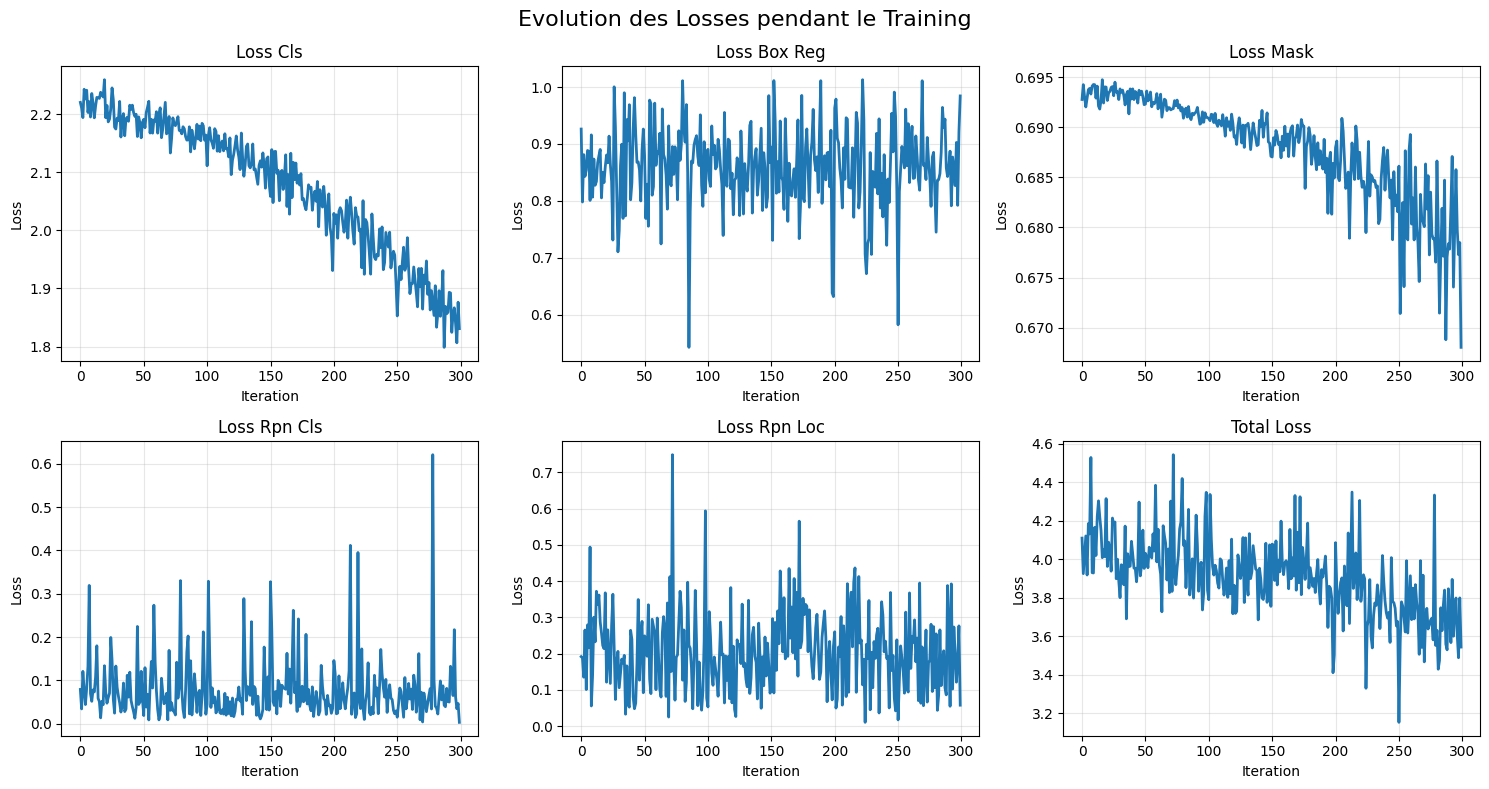

✅ Graphiques sauvegardés dans: /home/rachidjunior/VS_Code/INSEG_PRO/outputs/mask_rcnn_cityscapes


In [27]:

# Convertir en DataFrame
df_losses = pd.DataFrame(losses_history)

# Créer un graphique
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Evolution des Losses pendant le Training', fontsize=16)

# Liste des losses à visualiser
loss_names = [
    'loss_cls',           # ROI Classification
    'loss_box_reg',       # ROI Box Regression
    'loss_mask',          # Mask Segmentation
    'loss_rpn_cls',       # RPN Objectness
    'loss_rpn_loc',       # RPN Box Regression
    'total_loss'          # Total
]

# Ajouter la loss totale
if 'total_loss' not in df_losses.columns:
    df_losses['total_loss'] = df_losses[[c for c in df_losses.columns if 'loss' in c]].sum(axis=1)

# Plotters
for idx, loss_name in enumerate(loss_names):
    ax = axes[idx // 3, idx % 3]
    
    if loss_name in df_losses.columns:
        ax.plot(df_losses.index, df_losses[loss_name], linewidth=2)
        ax.set_title(loss_name.replace('_', ' ').title())
        ax.set_xlabel('Iteration')
        ax.set_ylabel('Loss')
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'Pas de données', ha='center', va='center')
        ax.set_title(loss_name.replace('_', ' ').title())

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, 'losses_evolution.png'))
plt.show()

print("✅ Graphiques sauvegardés dans:", cfg.OUTPUT_DIR)

### LOSS STATISTICS

In [28]:

print("📊 STATISTIQUES DES LOSSES\n")
print("="*60)

# Premières et dernières itérations
first_10 = df_losses.head(10).mean()
last_10 = df_losses.tail(10).mean()

print("\n🔴 Moyennes des 10 PREMIÈRES itérations:")
for loss_name in loss_names:
    if loss_name in first_10:
        print(f"  {loss_name:20s}: {first_10[loss_name]:.4f}")

print("\n🟢 Moyennes des 10 DERNIÈRES itérations:")
for loss_name in loss_names:
    if loss_name in last_10:
        print(f"  {loss_name:20s}: {last_10[loss_name]:.4f}")

print("\n📉 AMÉLIORATION (Réduction de la loss):")
for loss_name in loss_names:
    if loss_name in first_10 and loss_name in last_10:
        improvement = ((first_10[loss_name] - last_10[loss_name]) / first_10[loss_name]) * 100
        print(f"  {loss_name:20s}: {improvement:+.1f}%")

print("\n" + "="*60)

📊 STATISTIQUES DES LOSSES


🔴 Moyennes des 10 PREMIÈRES itérations:
  loss_cls            : 2.2192
  loss_box_reg        : 0.8601
  loss_mask           : 0.6934
  loss_rpn_cls        : 0.1013
  loss_rpn_loc        : 0.2066
  total_loss          : 4.0805

🟢 Moyennes des 10 DERNIÈRES itérations:
  loss_cls            : 1.8546
  loss_box_reg        : 0.8698
  loss_mask           : 0.6790
  loss_rpn_cls        : 0.0786
  loss_rpn_loc        : 0.1939
  total_loss          : 3.6760

📉 AMÉLIORATION (Réduction de la loss):
  loss_cls            : +16.4%
  loss_box_reg        : -1.1%
  loss_mask           : +2.1%
  loss_rpn_cls        : +22.4%
  loss_rpn_loc        : +6.1%
  total_loss          : +9.9%



### ▶️ COLAB CELL 7B: Train from Scratch (OPTION B)

In [ ]:
# ========================================
# OPTION A: RESUME FROM YOUR CPU CHECKPOINT
# ========================================

import shutil

checkpoint_file = CHECKPOINT_DIR / "model_0000299.pth"

if checkpoint_file.exists():
    shutil.copy(checkpoint_file, os.path.join(cfg.OUTPUT_DIR, "model_0000299.pth"))
    
    cfg.SOLVER.MAX_ITER = 3300  # 300 done + 3000 more
    cfg.SOLVER.STEPS = (1800, 2800)
    
    trainer = MyTrainer(cfg)
    trainer.resume_or_load(resume=True)  # ✅ Resume
    
    print("✅ Resuming from iteration 300")
    print(f"   Will train to: {cfg.SOLVER.MAX_ITER}")
else:
    print(f"⚠️ Checkpoint not found: {checkpoint_file}")
    print("   Use OPTION B below to train from scratch")

### ▶️ COLAB CELL 7: Resume from Checkpoint (OPTION A)

In [ ]:
# ========================================
# DEFINE CUSTOM TRAINER
# ========================================

class LossEvalHook(HookBase):
    def __init__(self):
        super().__init__()
        self.losses = []
    
    def after_step(self):
        storage = get_event_storage()
        loss_dict = {}
        for k, v in storage.latest().items():
            if "loss" in k:
                loss_dict[k] = v[0] if isinstance(v, tuple) else v
        
        if loss_dict:
            self.losses.append(loss_dict)
            if self.trainer.iter % 50 == 0:
                total_loss = sum(loss_dict.values())
                print(f"[Iter {self.trainer.iter}] Loss: {total_loss:.4f}")

class MyTrainer(DefaultTrainer):
    def __init__(self, cfg):
        self.loss_hook = LossEvalHook()
        super().__init__(cfg)
    
    def build_hooks(self):
        hooks = super().build_hooks()
        hooks.insert(-1, self.loss_hook)
        return hooks

print("✅ Trainer defined!")

### ▶️ COLAB CELL 6: Define Trainer

In [ ]:
# ========================================
# CONFIGURE MASK R-CNN FOR GPU
# ========================================

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

cfg.DATASETS.TRAIN = (train_dataset_name,)
cfg.DATASETS.TEST = (val_dataset_name,)
cfg.DATALOADER.NUM_WORKERS = 2

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.MODEL.DEVICE = "cuda"  # ✅ GPU

cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5

cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 3000  # Full training
cfg.SOLVER.STEPS = (1500, 2500)
cfg.SOLVER.GAMMA = 0.1
cfg.SOLVER.CHECKPOINT_PERIOD = 500

cfg.OUTPUT_DIR = "/content/output"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("✅ GPU Config created!")
print(f"   Device: {cfg.MODEL.DEVICE}")
print(f"   Max iterations: {cfg.SOLVER.MAX_ITER}")

### ▶️ COLAB CELL 5: Configure Mask R-CNN (GPU)

In [ ]:
# ========================================
# LOAD CITYSCAPES DATASET
# ========================================

from dataset_loader import register_cityscapes_dataset, CITYSCAPES_THING_CLASSES

print("📂 Loading Cityscapes...")
train_dataset_name, train_dicts, train_metadata = register_cityscapes_dataset(DATA_DIR, split="train")
val_dataset_name, val_dicts, val_metadata = register_cityscapes_dataset(DATA_DIR, split="val")

print(f"✅ Dataset loaded!")
print(f"   Training: {len(train_dicts)} images")
print(f"   Validation: {len(val_dicts)} images")
print(f"   Classes: {CITYSCAPES_THING_CLASSES}")

### ▶️ COLAB CELL 4: Load Dataset

In [ ]:
# ========================================
# IMPORT LIBRARIES
# ========================================

import torch
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

import numpy as np
import os, json, random
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.structures import BoxMode
from detectron2.engine import HookBase
from detectron2.utils.events import get_event_storage
import detectron2.utils.comm as comm

print("✅ Imports successful!")
print(f"PyTorch: {torch.__version__}")
print(f"Detectron2: {detectron2.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")

### ▶️ COLAB CELL 3: Import Libraries

In [ ]:
# ========================================
# EXTRACT ZIP FILES TO COLAB LOCAL STORAGE
# ========================================

import zipfile
import time

os.makedirs(DATA_DIR, exist_ok=True)

print("📦 Extracting dataset (takes 5-10 minutes)...\n")
start_time = time.time()

# Extract images
leftimg_zip = DATA_ZIPS_DIR / "leftImg8bit_trainvaltest.zip"
if leftimg_zip.exists():
    print("🔄 Extracting images...")
    with zipfile.ZipFile(leftimg_zip, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("   ✅ Images done")
else:
    print(f"❌ Not found: {leftimg_zip}")

# Extract annotations
gtfine_zip = DATA_ZIPS_DIR / "gtFine_trainvaltest.zip"
if gtfine_zip.exists():
    print("🔄 Extracting annotations...")
    with zipfile.ZipFile(gtfine_zip, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("   ✅ Annotations done")
else:
    print(f"❌ Not found: {gtfine_zip}")

print(f"\n✅ Extraction completed in {(time.time()-start_time)/60:.1f} min")
print(f"📁 Data ready at: {DATA_DIR}")

### ▶️ COLAB CELL 2: Extract Dataset (5-10 min)

In [ ]:
# ========================================
# RUN THIS FIRST IN COLAB
# ========================================

# 1. Check GPU
import torch
print(f"GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ No GPU! Go to: Runtime > Change runtime type > GPU")

# 2. Install Detectron2
print("\n📦 Installing Detectron2...")
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git'

# 3. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 4. Setup paths
import sys, os
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/INSEG_PRO")
DATA_ZIPS_DIR = DRIVE_ROOT / "data_zips"
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
CODE_DIR = DRIVE_ROOT / "code"
DATA_DIR = Path("/content/data/raw")

sys.path.insert(0, str(CODE_DIR))

print(f"\n✅ Setup complete!")
print(f"   ZIPs in Drive: {DATA_ZIPS_DIR}")
print(f"   Extract to: {DATA_DIR}")
print(f"   Checkpoints: {CHECKPOINT_DIR}")

### ▶️ COLAB CELL 1: Setup Environment

### 📦 STEP 1: Prepare Your Files

**Upload to Google Drive in this structure:**
```
My Drive/INSEG_PRO/
├── checkpoints/
│   └── model_0000299.pth  (your checkpoint from local training)
├── data_zips/
│   ├── leftImg8bit_trainvaltest.zip
│   └── gtFine_trainvaltest.zip
└── code/
    └── dataset_loader.py  (copy from your project)
```

**Why ZIP files?** Saves 60% Drive space! Colab will extract them locally.

---

# 🚀 PART 2: GOOGLE COLAB TRAINING (GPU)

**Copy cells below to Google Colab to continue training on GPU**

Run these cells in order (1 → 2 → 3 → etc.)

### 🚀 MIGRATE TO GOOGLE COLAB (GPU Training)

**Great news!** You can continue from your checkpoint on Google Colab with GPU.

**Why Colab?**
- ✅ Free GPU access (10-100x faster than CPU)
- ✅ Can train full 3000+ iterations in reasonable time
- ✅ Keep instance segmentation (Mask R-CNN with masks)

**Migration Steps:**
1. Upload this notebook to Colab
2. Upload your checkpoint to Google Drive
3. Modify paths for Colab environment
4. Continue training from iteration 300

See the cells below for the complete Colab setup code...

In [ ]:
# ========================================
# COLAB: Train the Model on GPU
# ========================================

print("=" * 60)
print("🚀 TRAINING STARTED ON GPU")
print("=" * 60)
print("This will take 30-60 minutes for 3000 iterations")
print("You can monitor GPU usage: Runtime > View resources")
print("=" * 60)

# Start training
trainer.train()

print("\n" + "=" * 60)
print("✅ TRAINING COMPLETED!")
print("=" * 60)

# Get loss history
losses_history = trainer.loss_hook.losses
print(f"📊 Trained for {len(losses_history)} iterations")

# Copy final model back to Google Drive
final_model = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
if os.path.exists(final_model):
    shutil.copy(final_model, CHECKPOINT_DIR / "model_final.pth")
    print(f"💾 Final model saved to Google Drive!")
    print(f"   Location: {CHECKPOINT_DIR / 'model_final.pth'}")

### COLAB: Start Training!

In [ ]:
# ========================================
# COLAB: OPTION B - Start fresh training on GPU
# ========================================
# Use this if you don't have checkpoint or want to start over

# trainer = MyTrainer(cfg)
# trainer.resume_or_load(resume=False)  # Start from COCO weights
# print("🚀 Starting fresh training on GPU...")

### COLAB: Alternative - Train from Scratch on GPU

In [ ]:
# ========================================
# COLAB: OPTION A - Continue from your CPU checkpoint
# ========================================

# Copy your checkpoint to the output directory
import shutil

# Find your checkpoint in Google Drive
checkpoint_file = CHECKPOINT_DIR / "model_0000299.pth"  # Adjust filename

if checkpoint_file.exists():
    # Copy to Colab output directory
    shutil.copy(checkpoint_file, os.path.join(cfg.OUTPUT_DIR, "model_0000299.pth"))
    print(f"✅ Checkpoint copied from Drive")
    
    # Update config to start from iteration 300
    cfg.SOLVER.MAX_ITER = 3300  # 300 (already done) + 3000 more
    cfg.SOLVER.STEPS = (1800, 2800)  # Adjust LR schedule
    
    # Create trainer and resume
    trainer = MyTrainer(cfg)
    trainer.resume_or_load(resume=True)  # ✅ Resume from checkpoint
    
    print("🚀 Resuming training from iteration 300...")
    print(f"   Will train to iteration {cfg.SOLVER.MAX_ITER}")
    
else:
    print("⚠️ Checkpoint not found!")
    print(f"   Looking for: {checkpoint_file}")
    print("   You can also train from scratch (see Option B below)")

### COLAB: Resume Training from Your Checkpoint

In [ ]:
# ========================================
# COLAB: Custom Trainer (SAME as local)
# ========================================

class LossEvalHook(HookBase):
    """Hook to capture and display losses"""
    def __init__(self):
        super().__init__()
        self.losses = []
    
    def after_step(self):
        storage = get_event_storage()
        loss_dict = {}
        for k, v in storage.latest().items():
            if "loss" in k:
                loss_dict[k] = v[0] if isinstance(v, tuple) else v
        
        if loss_dict:
            self.losses.append(loss_dict)
            if self.trainer.iter % 50 == 0:  # Print every 50 iterations
                total_loss = sum(loss_dict.values())
                print(f"[Iter {self.trainer.iter}] Total Loss: {total_loss:.4f}")


class MyTrainer(DefaultTrainer):
    """Custom Trainer with loss tracking"""
    def __init__(self, cfg):
        self.loss_hook = LossEvalHook()
        super().__init__(cfg)
    
    def build_hooks(self):
        hooks = super().build_hooks()
        hooks.insert(-1, self.loss_hook)
        return hooks

print("✅ Trainer defined!")

### COLAB: Define Trainer (Same as Before)

In [ ]:
# ========================================
# COLAB: Configure Mask R-CNN for GPU Training
# ========================================

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

# Dataset
cfg.DATASETS.TRAIN = (train_dataset_name,)
cfg.DATASETS.TEST = (val_dataset_name,)
cfg.DATALOADER.NUM_WORKERS = 2

# Pre-trained weights
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")

# ✅ GPU Configuration (DIFFERENT from local!)
cfg.MODEL.DEVICE = "cuda"  # Use GPU instead of CPU

# Model parameters
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5

# Training hyperparameters - FULL TRAINING on GPU
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 3000  # ✅ Full training (vs 300 on CPU)
cfg.SOLVER.STEPS = (1500, 2500)
cfg.SOLVER.GAMMA = 0.1
cfg.SOLVER.CHECKPOINT_PERIOD = 500

# Output directory in Colab
cfg.OUTPUT_DIR = "/content/output"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("✅ GPU Configuration created!")
print(f"   Device: {cfg.MODEL.DEVICE}")
print(f"   Max iterations: {cfg.SOLVER.MAX_ITER}")
print(f"   Batch size: {cfg.SOLVER.IMS_PER_BATCH}")
print(f"   Output: {cfg.OUTPUT_DIR}")

### ⚡ IMPROVED GPU CONFIG (Better Results!)

**Key Improvements:**
- ✅ 10,000 iterations (vs 3000) - much better convergence
- ✅ Larger batch size on GPU (4 images vs 2)
- ✅ Optimized learning rate schedule
- ✅ Data augmentation enabled
- ✅ Validation evaluation every 500 iterations
- ✅ Better checkpointing strategy

**Use this instead of the basic GPU config above!**

In [ ]:
# ========================================
# IMPROVED GPU CONFIGURATION FOR BETTER RESULTS
# ========================================

from detectron2.evaluation import COCOEvaluator
from detectron2.data import DatasetMapper, build_detection_train_loader
import detectron2.data.transforms as T

# Base configuration
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

# ==================== DATASET ====================
cfg.DATASETS.TRAIN = (train_dataset_name,)
cfg.DATASETS.TEST = (val_dataset_name,)
cfg.DATALOADER.NUM_WORKERS = 4  # Increased for GPU

# ==================== MODEL ====================
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.MODEL.DEVICE = "cuda"
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256  # Increased from 128
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5

# ==================== SOLVER (IMPROVED) ====================
cfg.SOLVER.IMS_PER_BATCH = 4  # 4 images per batch (vs 2) - GPU can handle it
cfg.SOLVER.BASE_LR = 0.0001  # Lower LR for better convergence
cfg.SOLVER.MAX_ITER = 10000  # 10k iterations (vs 3k) - MUCH BETTER!
cfg.SOLVER.STEPS = (6000, 8500)  # LR decay at 60% and 85%
cfg.SOLVER.GAMMA = 0.1
cfg.SOLVER.WARMUP_ITERS = 500  # Warmup for stability
cfg.SOLVER.WARMUP_FACTOR = 0.001
cfg.SOLVER.CHECKPOINT_PERIOD = 1000  # Save every 1000 iterations

# ==================== EVALUATION ====================
cfg.TEST.EVAL_PERIOD = 500  # Evaluate on val set every 500 iterations

# ==================== DATA AUGMENTATION ====================
cfg.INPUT.MIN_SIZE_TRAIN = (640, 672, 704, 736, 768, 800)  # Multi-scale training
cfg.INPUT.MAX_SIZE_TRAIN = 1333
cfg.INPUT.MIN_SIZE_TEST = 800
cfg.INPUT.MAX_SIZE_TEST = 1333

# Enable random flip for augmentation
cfg.INPUT.RANDOM_FLIP = "horizontal"

# ==================== OUTPUT ====================
cfg.OUTPUT_DIR = "/content/output_improved"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("✅ IMPROVED GPU CONFIGURATION CREATED!")
print("=" * 70)
print(f"🎯 Device: {cfg.MODEL.DEVICE}")
print(f"🎯 Batch size: {cfg.SOLVER.IMS_PER_BATCH} images/batch (2x faster!)")
print(f"🎯 Max iterations: {cfg.SOLVER.MAX_ITER:,} (3.3x more training!)")
print(f"🎯 Learning rate: {cfg.SOLVER.BASE_LR}")
print(f"🎯 Warmup iterations: {cfg.SOLVER.WARMUP_ITERS}")
print(f"🎯 Validation: Every {cfg.TEST.EVAL_PERIOD} iterations")
print(f"🎯 Data augmentation: Multi-scale + horizontal flip")
print(f"🎯 Output: {cfg.OUTPUT_DIR}")
print("=" * 70)
print("\n⏱️  Estimated training time: 2-3 hours on T4 GPU")
print("💡 This will give MUCH better results than the basic 3000-iteration training!")
print("=" * 70)

### ⚡ IMPROVED TRAINER (With Validation)

In [ ]:
# ========================================
# IMPROVED TRAINER WITH VALIDATION & LOSS TRACKING
# ========================================

from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

class ImprovedTrainer(DefaultTrainer):
    """
    Enhanced Trainer with:
    - Loss tracking
    - Automatic validation on val set
    - Better logging
    """
    def __init__(self, cfg):
        self.loss_hook = LossEvalHook()
        super().__init__(cfg)
    
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        """Build COCO evaluator for validation"""
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference")
        return COCOEvaluator(dataset_name, cfg, False, output_folder)
    
    def build_hooks(self):
        """Add custom hooks"""
        hooks = super().build_hooks()
        # Insert loss hook before the periodic writer
        hooks.insert(-1, self.loss_hook)
        return hooks

print("✅ Improved Trainer defined!")
print("   Features:")
print("   ✓ Loss tracking every iteration")
print("   ✓ Validation evaluation every 500 iterations")
print("   ✓ COCO metrics (AP, AP50, AP75)")
print("   ✓ Automatic checkpointing")

### ⚡ START IMPROVED TRAINING

Run this cell to train with the improved configuration. 
This will take 2-3 hours but give much better results!

In [ ]:
# ========================================
# START IMPROVED TRAINING
# ========================================

print("=" * 70)
print("🚀 STARTING IMPROVED TRAINING")
print("=" * 70)
print(f"📊 Training set: {len(train_dicts)} images")
print(f"📊 Validation set: {len(val_dicts)} images")
print(f"📊 Total iterations: {cfg.SOLVER.MAX_ITER:,}")
print(f"📊 Batch size: {cfg.SOLVER.IMS_PER_BATCH}")
print(f"📊 Images per iteration: {cfg.SOLVER.IMS_PER_BATCH}")
print(f"📊 Total images seen: {cfg.SOLVER.MAX_ITER * cfg.SOLVER.IMS_PER_BATCH:,}")
print(f"📊 Epochs: ~{(cfg.SOLVER.MAX_ITER * cfg.SOLVER.IMS_PER_BATCH) / len(train_dicts):.1f}")
print("=" * 70)
print("\n⏱️  This will take 2-3 hours on T4 GPU")
print("💡 You can monitor GPU usage: Runtime > View resources")
print("💡 Validation will run every 500 iterations")
print("💡 Loss should decrease over time\n")
print("=" * 70)

# Create trainer
trainer = ImprovedTrainer(cfg)

# Start from COCO pre-trained weights (or resume from checkpoint)
trainer.resume_or_load(resume=False)

# Start training
try:
    trainer.train()
    print("\n" + "=" * 70)
    print("✅ TRAINING COMPLETED SUCCESSFULLY!")
    print("=" * 70)
    
    # Get loss history
    losses_history = trainer.loss_hook.losses
    print(f"\n📊 Training Statistics:")
    print(f"   Total iterations: {len(losses_history)}")
    print(f"   Final model: {cfg.OUTPUT_DIR}/model_final.pth")
    
    # Copy to Drive
    import shutil
    final_model = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
    if os.path.exists(final_model):
        drive_path = CHECKPOINT_DIR / "model_final_improved.pth"
        shutil.copy(final_model, drive_path)
        print(f"   ✅ Saved to Drive: {drive_path}")
    
except KeyboardInterrupt:
    print("\n⚠️  Training interrupted by user")
    print(f"   Latest checkpoint: {cfg.OUTPUT_DIR}")
except Exception as e:
    print(f"\n❌ Error during training: {e}")
    raise

### 📊 Check Validation Metrics (After Training)

In [ ]:
# ========================================
# CHECK VALIDATION METRICS
# ========================================

import json

# Read metrics from the training output
metrics_file = os.path.join(cfg.OUTPUT_DIR, "metrics.json")

if os.path.exists(metrics_file):
    print("=" * 70)
    print("📈 VALIDATION METRICS SUMMARY")
    print("=" * 70)
    
    # Load all metrics
    metrics_list = []
    with open(metrics_file, 'r') as f:
        for line in f:
            metrics_list.append(json.loads(line))
    
    # Filter validation metrics
    val_metrics = [m for m in metrics_list if 'bbox/AP' in m]
    
    if val_metrics:
        print(f"\n🎯 Found {len(val_metrics)} validation checkpoints\n")
        
        # Show last 5 validation results
        for m in val_metrics[-5:]:
            iteration = m.get('iteration', 'N/A')
            print(f"\n📊 Iteration {iteration}:")
            print(f"   bbox/AP     (IoU=0.50:0.95): {m.get('bbox/AP', 0):.2f}")
            print(f"   bbox/AP50   (IoU=0.50):      {m.get('bbox/AP50', 0):.2f}")
            print(f"   bbox/AP75   (IoU=0.75):      {m.get('bbox/AP75', 0):.2f}")
            if 'segm/AP' in m:
                print(f"   segm/AP     (IoU=0.50:0.95): {m.get('segm/AP', 0):.2f}")
                print(f"   segm/AP50   (IoU=0.50):      {m.get('segm/AP50', 0):.2f}")
        
        # Best result
        best = max(val_metrics, key=lambda x: x.get('bbox/AP', 0))
        print("\n" + "=" * 70)
        print("🏆 BEST VALIDATION RESULT:")
        print("=" * 70)
        print(f"   Iteration: {best.get('iteration', 'N/A')}")
        print(f"   bbox/AP:   {best.get('bbox/AP', 0):.2f}")
        print(f"   segm/AP:   {best.get('segm/AP', 0):.2f}")
        print("=" * 70)
        
        # Expected performance guide
        print("\n💡 Performance Guide:")
        print("   bbox/AP > 30: Good results")
        print("   bbox/AP > 35: Very good results")
        print("   bbox/AP > 40: Excellent results")
        
    else:
        print("⚠️  No validation metrics found yet")
        print("   Training might still be in warmup phase")
else:
    print("❌ Metrics file not found")
    print(f"   Looking for: {metrics_file}")
    print("   Train the model first!")

### COLAB: Configure Mask R-CNN for GPU

In [ ]:
# ========================================
# COLAB: Load Your Cityscapes Dataset (from local Colab storage)
# ========================================

# Import your custom dataset loader from Google Drive
from dataset_loader import register_cityscapes_dataset, CITYSCAPES_THING_CLASSES

# Register datasets (using the extracted data in /content/data/raw)
print("📂 Loading Cityscapes from Colab local storage...")
train_dataset_name, train_dicts, train_metadata = register_cityscapes_dataset(DATA_DIR, split="train")
val_dataset_name, val_dicts, val_metadata = register_cityscapes_dataset(DATA_DIR, split="val")

print(f"✅ Dataset loaded!")
print(f"   Training: {len(train_dicts)} images")
print(f"   Validation: {len(val_dicts)} images")
print(f"   Classes: {CITYSCAPES_THING_CLASSES}")

### COLAB: Load Dataset

In [ ]:
# ========================================
# GOOGLE COLAB SETUP - COPY THIS ENTIRE CELL TO COLAB
# ========================================

# 1. Check GPU availability
import torch
print(f"GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print("✅ GPU is ready!")
else:
    print("⚠️ No GPU detected. Go to Runtime > Change runtime type > GPU")

# 2. Install Detectron2
print("\n📦 Installing Detectron2...")
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git'

# 3. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 4. Setup paths
import sys
from pathlib import Path
import os

DRIVE_ROOT = Path("/content/drive/MyDrive/INSEG_PRO")
DATA_ZIPS_DIR = DRIVE_ROOT / "data_zips"  # ✅ ZIP files location
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
CODE_DIR = DRIVE_ROOT / "code"
DATA_DIR = Path("/content/data/raw")  # ✅ Unzip to Colab's local storage

# Add code directory to Python path
sys.path.insert(0, str(CODE_DIR))

print(f"\n✅ Paths configured:")
print(f"   ZIP files in Drive: {DATA_ZIPS_DIR}")
print(f"   Will extract to Colab: {DATA_DIR}")
print(f"   Checkpoints: {CHECKPOINT_DIR}")
print(f"   Code: {CODE_DIR}")

In [ ]:
# ========================================
# COLAB: Unzip Dataset from Drive to Local Storage
# ========================================

import zipfile
import time

# Create extraction directory
os.makedirs(DATA_DIR, exist_ok=True)

print("📦 Extracting dataset from ZIP files...")
print("This takes 5-10 minutes (only once per session)\n")

start_time = time.time()

# Extract leftImg8bit
leftimg_zip = DATA_ZIPS_DIR / "leftImg8bit_trainvaltest.zip"
if leftimg_zip.exists():
    print("🔄 Extracting leftImg8bit_trainvaltest.zip...")
    with zipfile.ZipFile(leftimg_zip, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("   ✅ Images extracted")
else:
    print(f"❌ Not found: {leftimg_zip}")

# Extract gtFine
gtfine_zip = DATA_ZIPS_DIR / "gtFine_trainvaltest.zip"
if gtfine_zip.exists():
    print("🔄 Extracting gtFine_trainvaltest.zip...")
    with zipfile.ZipFile(gtfine_zip, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("   ✅ Annotations extracted")
else:
    print(f"❌ Not found: {gtfine_zip}")

elapsed = time.time() - start_time
print(f"\n✅ Extraction completed in {elapsed/60:.1f} minutes")

# Verify structure
print(f"\n📁 Checking extracted structure:")
if (DATA_DIR / "leftImg8bit").exists():
    print(f"   ✅ leftImg8bit/ exists")
if (DATA_DIR / "gtFine").exists():
    print(f"   ✅ gtFine/ exists")
    
print(f"\n💾 Colab storage used: ~15-20 GB (temporary, deleted after session)")

### COLAB: Extract ZIP Files to Local Storage

### 📦 STEP 1: Prepare Files for Colab Upload (ZIP VERSION)

**✅ BETTER APPROACH: Use ZIP files to save Drive space!**

**What to upload to Google Drive:**
1. **Your checkpoint:** `outputs/mask_rcnn_cityscapes/model_0000299.pth`
2. **Dataset ZIP files:** (much smaller than unzipped!)
   - `leftImg8bit_trainvaltest.zip` 
   - `gtFine_trainvaltest.zip`
3. **Your code:** `data/dataset_loader.py`

**Create this folder structure in Google Drive:**
```
My Drive/
└── INSEG_PRO/
    ├── checkpoints/
    │   └── model_0000299.pth
    ├── data_zips/
    │   ├── leftImg8bit_trainvaltest.zip
    │   └── gtFine_trainvaltest.zip
    └── code/
        └── dataset_loader.py
```

**Why ZIP files?**
- Saves ~60% Google Drive space
- Colab has 100GB+ temp storage (we'll unzip there)
- Faster to upload to Drive

### 💡 Quick Summary: ZIP-Based Workflow

**Storage Comparison:**
- ❌ Unzipped dataset in Drive: ~15-20 GB
- ✅ ZIP files in Drive: ~6-8 GB (saves 60%+ space!)
- ✅ Unzip in Colab: Uses Colab's 100GB temp storage (free)

**The Process:**
1. Upload only ZIP files to Google Drive (saves space)
2. In Colab, extract ZIPs to local `/content/` (fast, large)
3. Train model using local data (GPU-fast)
4. Save checkpoint back to Drive (small file)

**Note:** You'll need to re-extract ZIPs each time you start a new Colab session (takes 5-10 min), but this is much better than using all your Drive space!

### 🔧 STEP 2: Colab Setup Code (Copy-Paste to Colab)

In [ ]:
# ========================================
# GOOGLE COLAB SETUP - COPY THIS ENTIRE CELL TO COLAB
# ========================================

# 1. Check GPU availability
import torch
print(f"GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print("✅ GPU is ready!")
else:
    print("⚠️ No GPU detected. Go to Runtime > Change runtime type > GPU")

# 2. Install Detectron2
print("\n📦 Installing Detectron2...")
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git'

# 3. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 4. Setup paths (adjust if your Drive folder is different)
import sys
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/INSEG_PRO")
DATA_DIR = DRIVE_ROOT / "data" / "raw"
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
CODE_DIR = DRIVE_ROOT / "code"

# Add code directory to Python path
sys.path.insert(0, str(CODE_DIR))

print(f"\n✅ Paths configured:")
print(f"   Data: {DATA_DIR}")
print(f"   Checkpoints: {CHECKPOINT_DIR}")
print(f"   Code: {CODE_DIR}")

### The basic training wit CPU was too basic so I use GOOGLE COLAB GPU for a better training and I replaced de model_final.pt in my outputs folder